**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Juan Manuel Cuevas Gaytan
*   MATRÍCULA: A01197813

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
	- **8 columnas numericas y 5 de texto**

In [2]:
loan_df = pd.read_csv('data/personal_loan.csv')
loan_df.set_index('ID', inplace=True)
loan_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   str    
 9   Securities Account  5037 non-null   str    
 10  CD Account          5037 non-null   str    
 11  Online              5037 non-null   str    
 12  CreditCard          5037 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 511.7 KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
	- **Elimine los registros en los que la edad era mayor a 100 años debido a que presentaban edades casi imposibles.**
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
	- **Tomando en cuenta las restricciones de valores, aplique filtros para eliminar registros que contenian valores que no encajaban en cualquiera de las columnas.**
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?
	- **60 registros eliminados representando un 1.19% del total.**

In [3]:
# Registros con edad mayor a 100 años
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [4]:
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


In [5]:
n_inicial = len(loan_df)

loan_df = loan_df[
		(loan_df['Age'] <= 100) &
		(loan_df['Experience'] >= 0) &
		(loan_df['Family'] >= 0) &
		(loan_df['Education'].isin([1, 2, 3])) &
		(loan_df['ZIP Code'] >= 10000)
	]

eliminados = n_inicial - len(loan_df)

print(eliminados)
print(eliminados / n_inicial * 100, '%')

60
1.1911852293031566 %


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [6]:
loan_df[['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']].describe()

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [7]:
print(loan_df['Personal Loan'].value_counts())
print(loan_df['Securities Account'].value_counts())
print(loan_df['CD Account'].value_counts())
print(loan_df['Online'].value_counts())
print(loan_df['CreditCard'].value_counts())

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64


In [8]:
loan_df[['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']] = loan_df[['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']].replace({'Yes': '1', 'No': '0'}).astype(int)

print(loan_df['Personal Loan'].value_counts())
print(loan_df['Securities Account'].value_counts())
print(loan_df['CD Account'].value_counts())
print(loan_df['Online'].value_counts())
print(loan_df['CreditCard'].value_counts())

Personal Loan
0    4492
1     485
Name: count, dtype: int64
Securities Account
0    4458
1     519
Name: count, dtype: int64
CD Account
0    4674
1     303
Name: count, dtype: int64
Online
1    2975
0    2002
Name: count, dtype: int64
CreditCard
0    3513
1    1464
Name: count, dtype: int64


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [9]:
print(loan_df.duplicated().sum())

36


In [10]:
loan_df = loan_df.drop_duplicates()
loan_df = loan_df.reset_index(drop=True)
print(len(loan_df))

4941


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [11]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(object)

loan_df['Education'] = pd.Categorical(loan_df['Education'], categories=[1, 2, 3], ordered=True)

loan_df[['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']] = loan_df[['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']].astype('category')

loan_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4941 entries, 0 to 4940
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4941 non-null   int64   
 1   Experience          4941 non-null   int64   
 2   Income              4941 non-null   int64   
 3   ZIP Code            4941 non-null   object  
 4   Family              4941 non-null   int64   
 5   CCAvg               4941 non-null   float64 
 6   Education           4941 non-null   category
 7   Mortgage            4941 non-null   int64   
 8   Personal Loan       4941 non-null   category
 9   Securities Account  4941 non-null   category
 10  CD Account          4941 non-null   category
 11  Online              4941 non-null   category
 12  CreditCard          4941 non-null   category
dtypes: category(6), float64(1), int64(5), object(1)
memory usage: 299.4+ KB


In [12]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

print(num_cols)
print(cat_cols)

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.
	- **Para 'Age' conto con un valor en la simetria de -0.022 lo que indica que tiene una distribucion casi simetrica sin cargarse para algun lado, y obtuvo un valor de curtosis de -1.16 lo que indica que hay distribucion pareja entre sus valores, con esto podemos ver que contando unicamente las edades de clientes en el registro, hay una distribucion casi pareja entre todas las edades.**
	- **Para 'Income' su valor de simetria es de 0.841, lo que indica que su distribucion esta mas cargada para el limite inferior y su valor de curtosis es de -0.04 que indica una distribucion casi normal, lo que puede indicar que solo unas cuantas personas llegan a ganar mucho y la mayoria mas moderado.**
	- **Para 'Mortgage' su valor de simetria es de 2.10 y su valor de curtosis es de 4.76 lo que indica una distribucion muy marcada y cargada al limite inferior, lo que indica que muy pocos clientes tienen una hipoteca muy alta.**

In [13]:
loan_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0


In [14]:
print(loan_df[num_cols].skew())

Age          -0.022754
Experience   -0.015216
Income        0.841991
Family        0.159463
CCAvg         1.594670
Mortgage      2.103865
dtype: float64


In [15]:
print(loan_df[num_cols].kurt())

Age          -1.161599
Experience   -1.134857
Income       -0.046164
Family       -1.403842
CCAvg         2.635545
Mortgage      4.760021
dtype: float64


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
	- **La mayoría de las comparaciones difieren de la curva normal. Hay algunas que llegan a tener características similares, como Age y Experience, cuyo centro es igual al de la normal, pero la forma de la campana es diferente, ya que son más planas. En Income, la altura es parecida, pero su centro y su simetría no. Las demás variables no llegan a tener las mismas características. Esto coincide con lo esperado según los valores de asimetría y curtosis, Age es simétrica y plana, Income tiene asimetría positiva y Mortgage tiene asimetría positiva con un pico muy alto.**
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?
	- **Age y Experience tienen valores similares en la media y mediana lo que puede explicar por que en su distribucion sea simetrica. Mientras que Income, CCAvg y Mortgage la media es mayor a la mediana lo que hace que la distribucion este mas cargada a la derecha.**

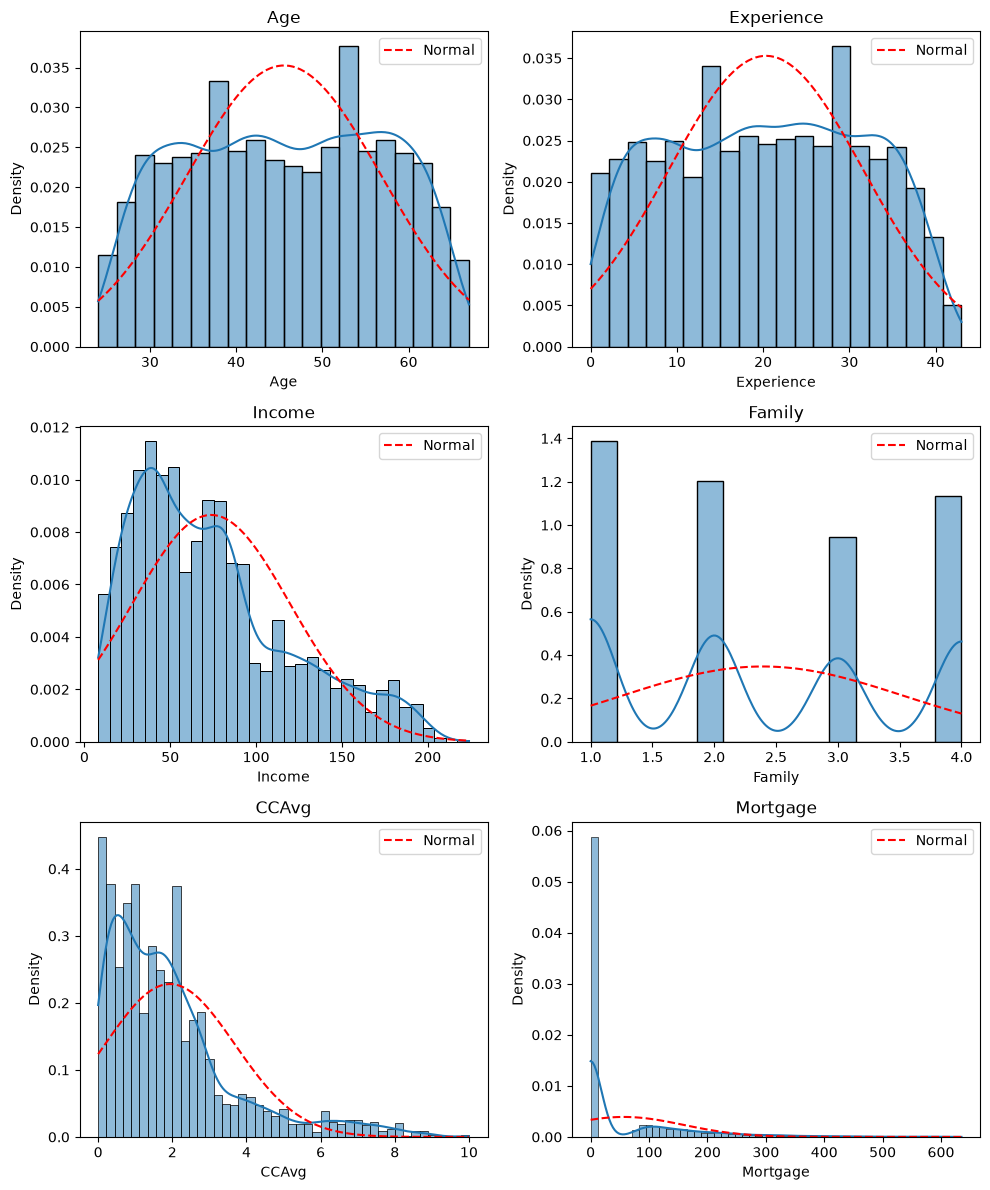

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for ax, col in zip(axes.flat, num_cols):
    datos = loan_df[col]
    x = np.linspace(datos.min(), datos.max(), 100)
    sns.histplot(datos, kde=True, stat='density', ax=ax)
    ax.plot(x, norm.pdf(x, loc=datos.mean(), scale=datos.std()), 'r--', label='Normal')
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

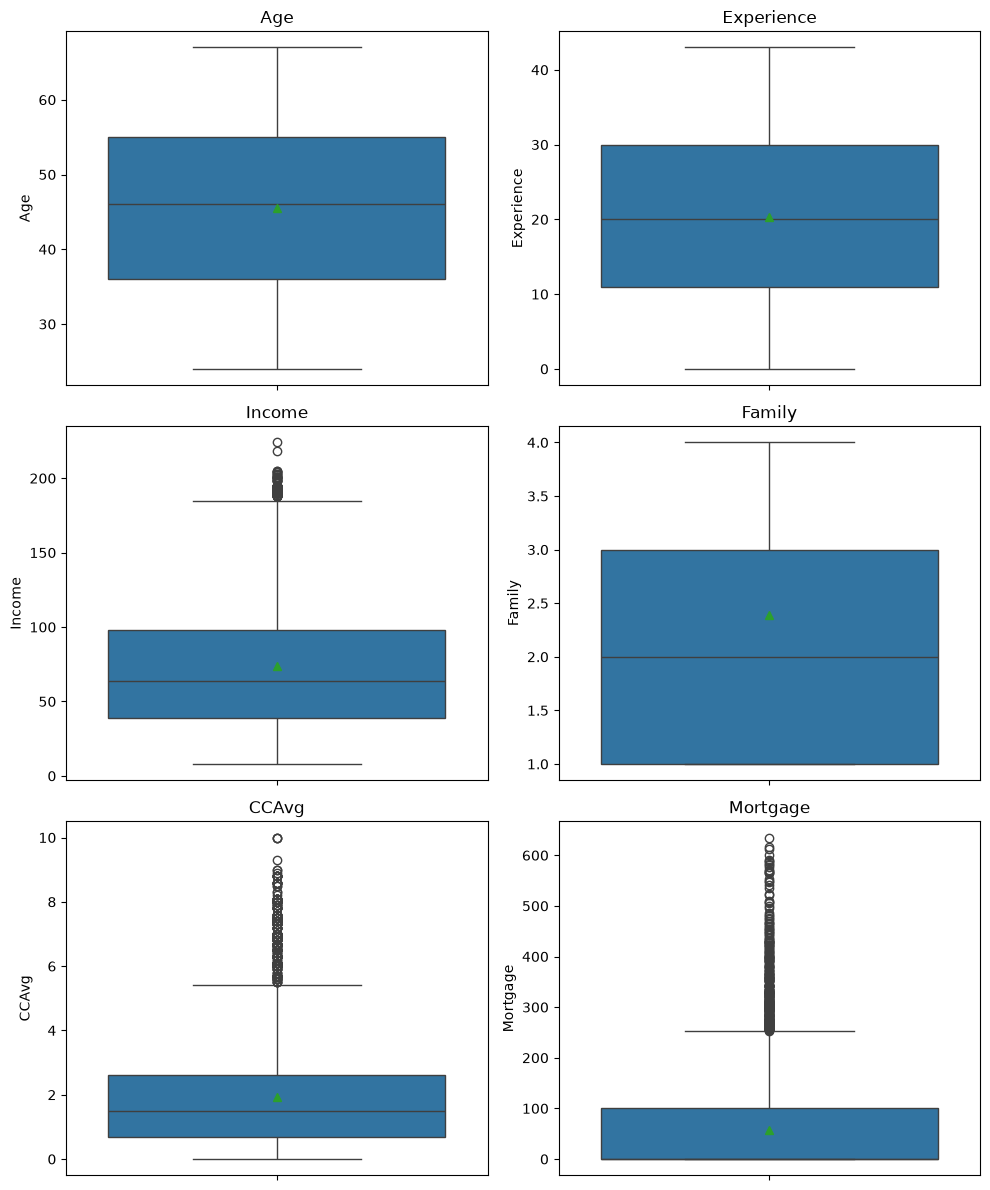

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=loan_df[col], showmeans=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [18]:
print(loan_df[num_cols].mean())

Age           45.560210
Experience    20.335357
Income        73.826553
Family         2.391621
CCAvg          1.935855
Mortgage      56.663631
dtype: float64


In [19]:
print(loan_df[num_cols].median())

Age           46.0
Experience    20.0
Income        64.0
Family         2.0
CCAvg          1.5
Mortgage       0.0
dtype: float64


8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [20]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


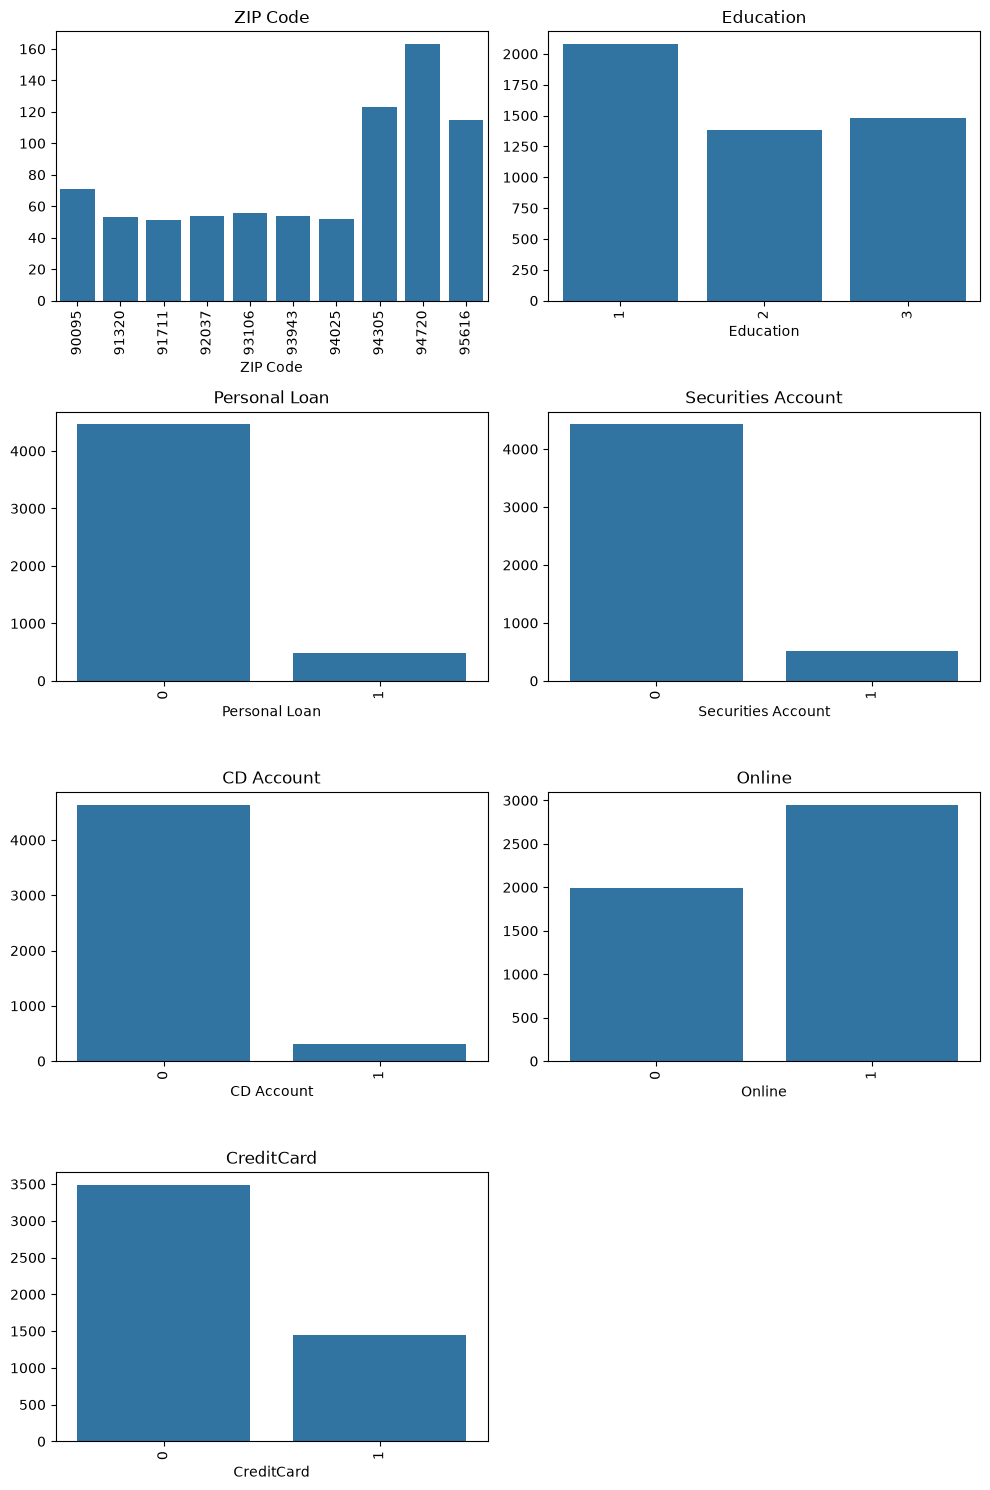

In [21]:
fig, axes = plt.subplots(4, 2, figsize=(10, 15))

for ax, col in zip(axes.flat, cat_cols):
    conteo = loan_df[col].value_counts().head(10)
    sns.barplot(x=conteo.index, y=conteo.values, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=90)
    
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
	- **Selecciono el par de Age y Experience, porque es el que tiene una correlacion casi de 1, lo que indica que si uno sube el otro tambien y en la grafica tambien se ve representada esta tendencia, y esto es esperado ya que mientras mas años mas experiencia.**
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?
	- **El valor de correlación obtenido entre Age y Experience es de 0.99, que indica una relación positiva casi perfecta. Esta correlacion se puede observar en el grafico de dispersion, los puntos forman una linea recta ascendente, ya que mientras el valor de Age aumenta, el de Experience tambien aumenta.**

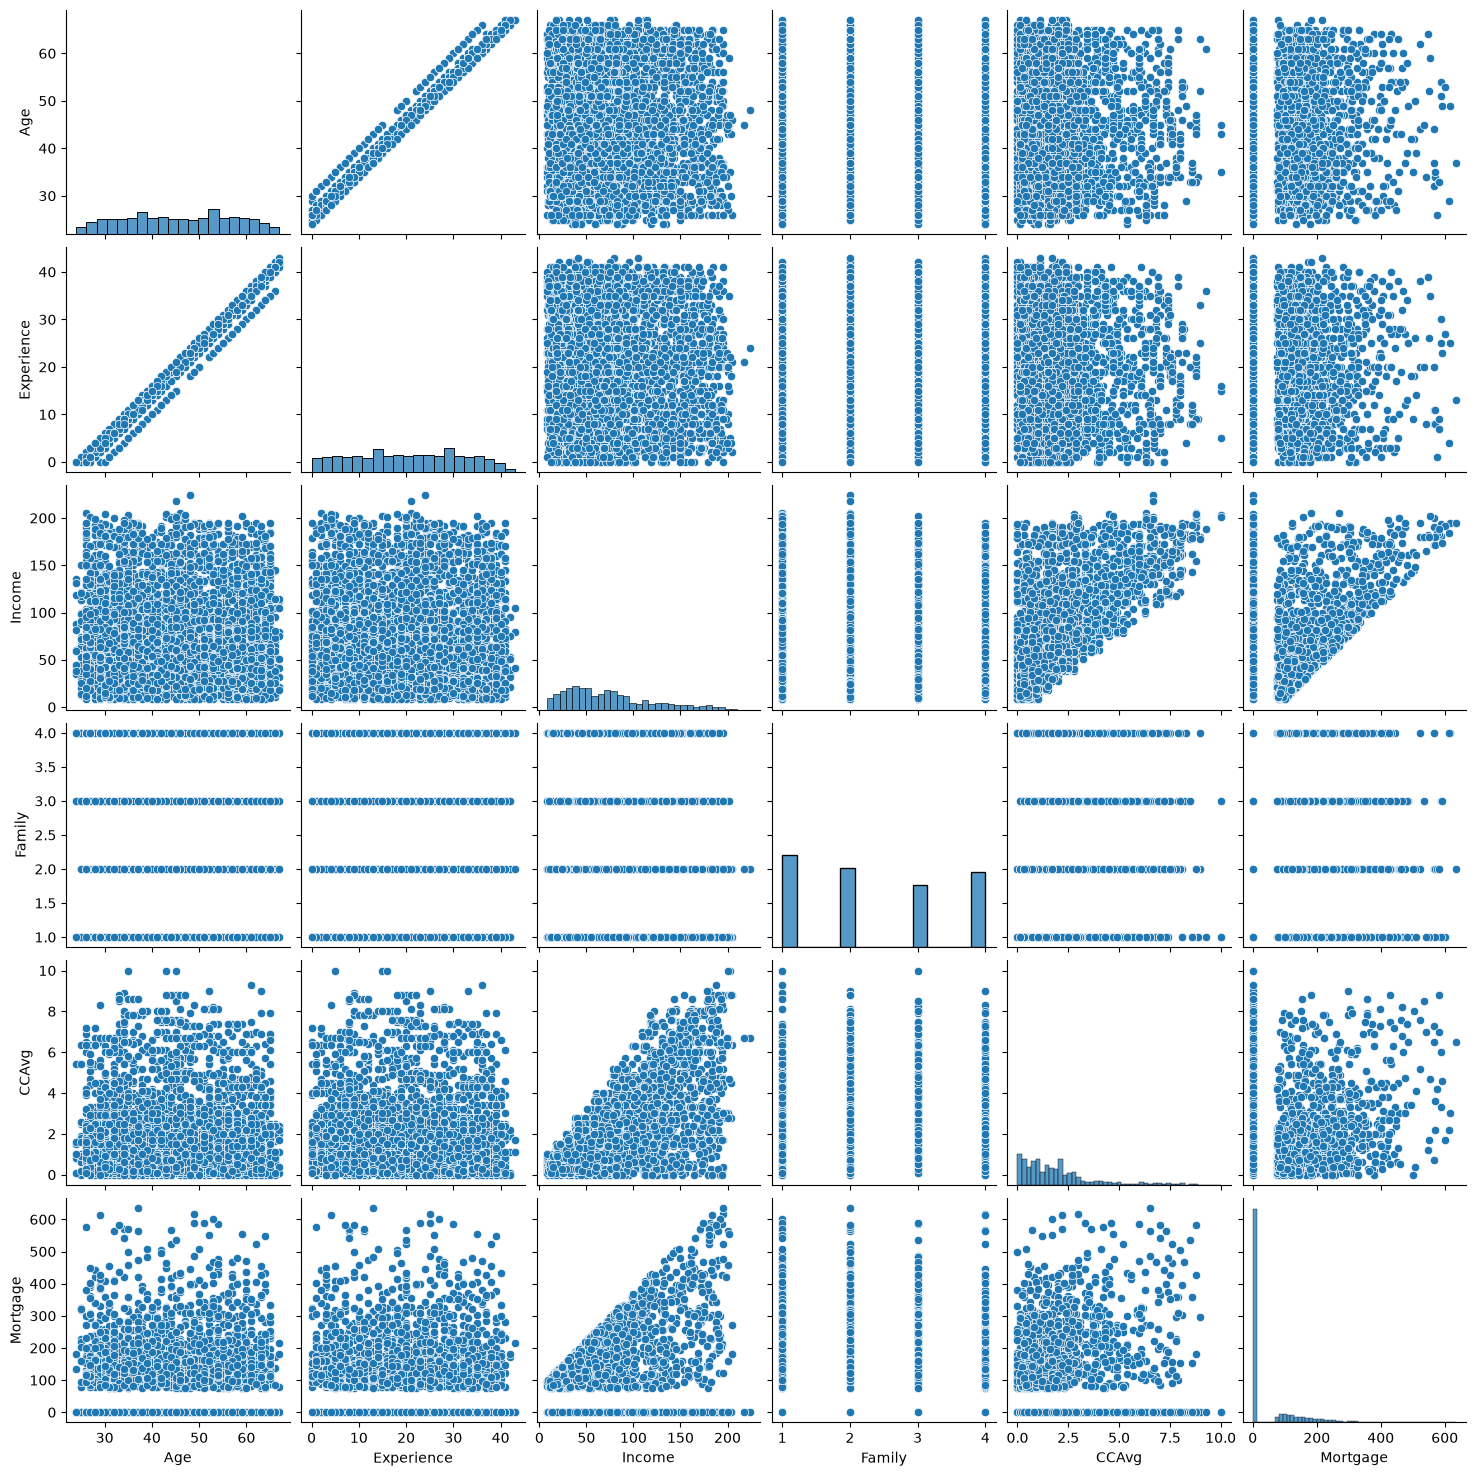

In [22]:
sns.pairplot(loan_df, vars=num_cols)
plt.show()

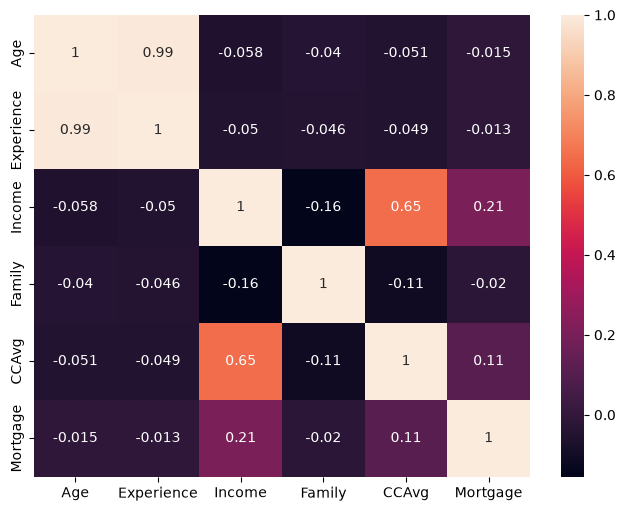

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True)
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.
	- **En el grupo de variables numericas, Income, CCAvg y Family son las que muestran una mayor diferencia entre los clientes que aceptaron el prestamo y los que no. Los que aceptaron tienen ingresos mas altos, gastan mas y tienen familias un poco mas grandes. Mientras que en Age y Experience no se observan diferencias entre ambos grupos.**
	- **Para el grupo de variables categoricas, la mayoria no presenta una diferencia en su distribucion de Personal Loan, en ambos casos la cantidad de clientes que aceptaron un prestamo es muy bajo. CD Account es una excepcion, donde casi la mitad de los clientes con CD Account si aceptaron un prestamo mientras que los que no tienen solo presentan una minoria. Tambien en Education los clientes con niveles 2 y 3 tienen una cantidad un poco mayor a los que tienen nivel 1 de educacion.**


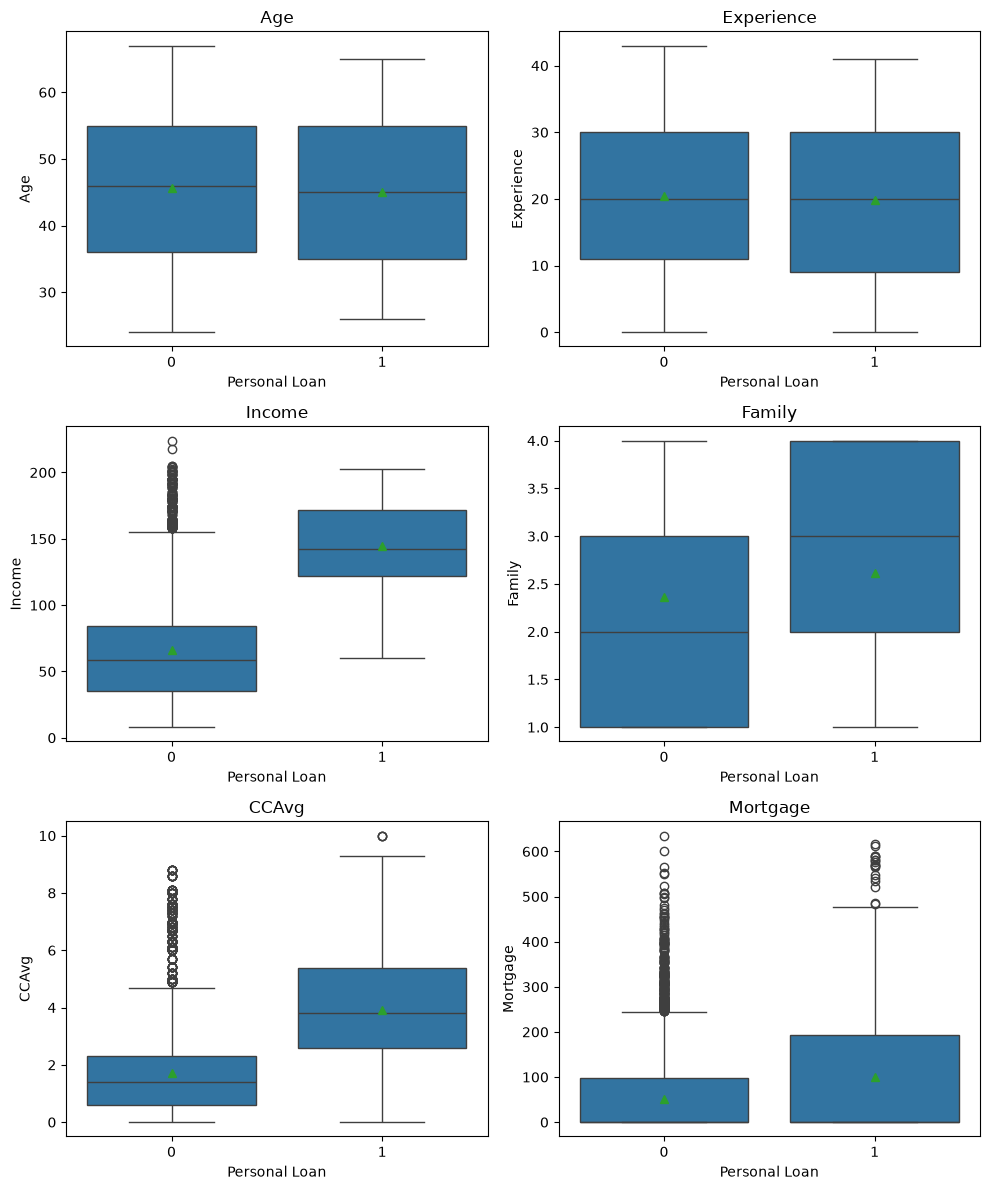

In [24]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=loan_df[['Personal Loan', col]], x='Personal Loan', y=col, showmeans=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

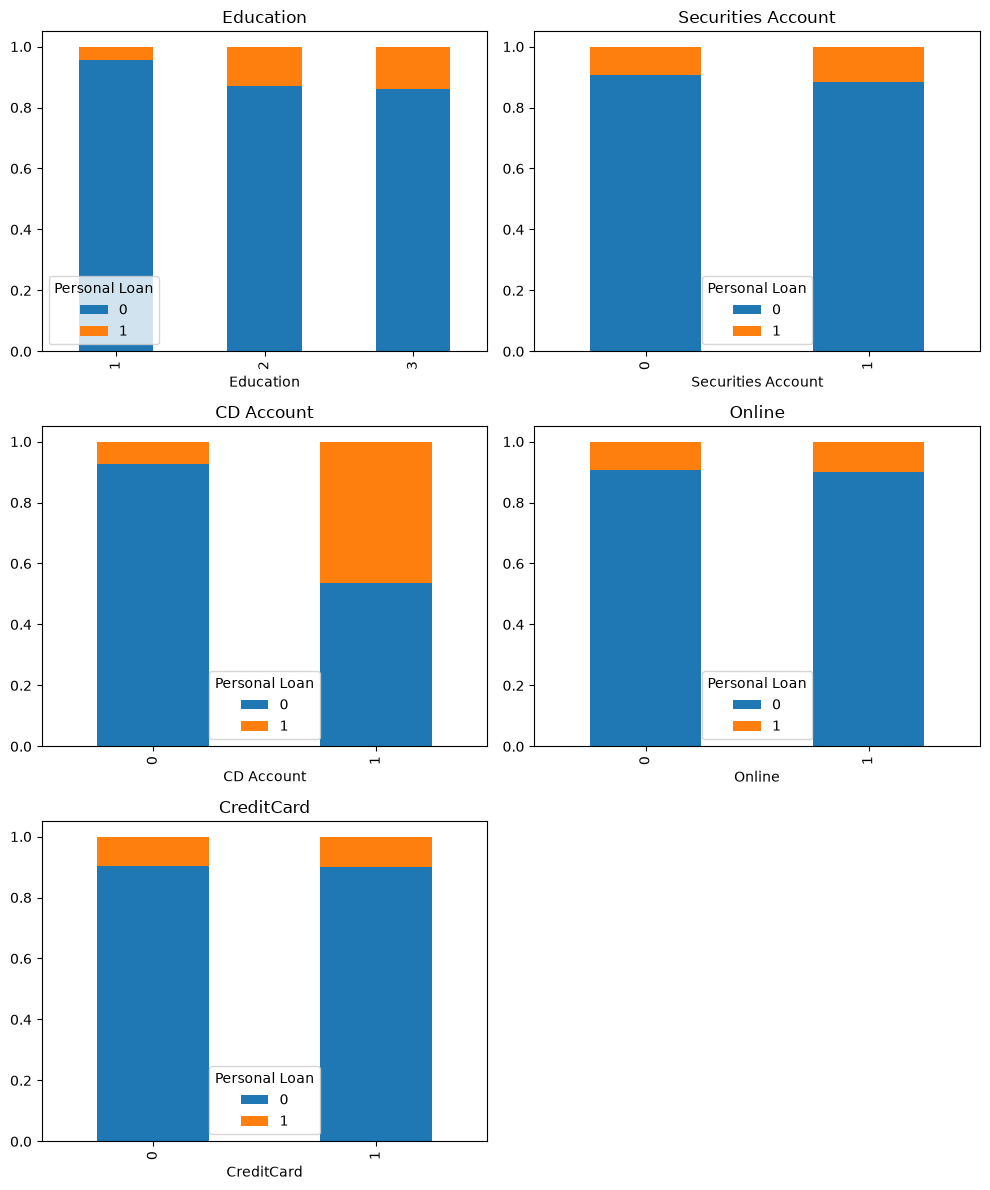

In [25]:
cat_analisis = ['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for ax, col in zip(axes.flat, cat_analisis):
    # Frecuencia cruzada, combinaciones de 11, 10, 01 y 00
    tabla = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index')
    tabla.plot(kind='bar', stacked=True, ax=ax, title=col)


axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

---

**Referencias**

* Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande], utilizado para generación de código, explicación de funciones y depuración de código. https://claude.ai/

* Kumar Mukhiya, S., y Ahmed, U. (2020). Hands-On Exploratory Data Analysis with Python. Packt Publishing.

* McKinney, W. (2022). Python for Data Analysis (3rd ed.). O'Reilly Media. 

* Pandas. (2026). Pandas Documentation [Documentación de software]. https://pandas.pydata.org/docs/index.html

* The Matplotlib Development Team. (2024). Matplotlib: Visualization with Python [Documentación]. https://matplotlib.org/

* Waskom, M. (2024). Seaborn: statistical data visualization [Documentación]. https://seaborn.pydata.org/

---